## 1. Récupération et exploration et préparation des données

In [1]:
# Manipulation et exploration des données
import pandas as pd
import numpy as np

# Exploration graphique
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrer les messages d'avertissements
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

**Chargement des données**

In [3]:
df = pd.read_csv('Dataset.csv')


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:
df.head()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    int64  
 3   Education                614 non-null    int64  
 4   Self_Employed            614 non-null    int64  
 5   Loan_Amount_Term         614 non-null    float64
 6   Credit_History           614 non-null    float64
 7   Loan_Status              614 non-null    int64  
 8   Total_Income_log         614 non-null    float64
 9   LoanAmount_log           614 non-null    float64
 10  Property_Area_Semiurban  614 non-null    int64  
 11  Property_Area_Urban      614 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 57.7 KB


**Traitement des valeurs manquantes**

In [4]:
# Remplacement par le mode pour les variables catégorielles
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remplacement par la médiane pour les variables numériques
numerical_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
###_Interprétation 
Variables catégorielles (`Gender`, `Married`, etc.) : j'ai remplacé les valeurs manquantes par le mode (la valeur la plus fréquente). C'est la méthode standard pour ne pas déformer la distribution des caractéristiques sociodémographiques des demandeurs de crédit.
Variables numériques (`LoanAmount`, `Loan_Amount_Term`) : j'ai choisi la médiane plutôt que la moyenne car le montant des prêts présente des valeurs extrêmes (quelques demandes de montants très élevés) qui auraient artificiellement biaisé la moyenne.

**Transformation et création des caractéristiques (Feature Engineering)**

In [6]:
# 1. Création de la variable Revenu Total et application du logarithme pour stabiliser la variance
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']
df['Total_Income_log'] = np.log(df['Total_Income'] + 1)
df['LoanAmount_log'] = np.log(df['LoanAmount'] + 1)

# 2. Nettoyage de la colonne Dependents
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)

# 3. Encodage numérique des variables catégorielles binaires
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Married'] = df['Married'].map({'Yes': 1, 'No': 0})
df['Education'] = df['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df['Self_Employed'] = df['Self_Employed'].map({'Yes': 1, 'No': 0})
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

# 4. Encodage de la variable Property_Area (Variables muettes / Dummy encoding)
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True, dtype=int)

# 5. Suppression des anciennes colonnes brutes non nécessaires pour les algorithmes
df = df.drop(columns=['Loan_ID', 'ApplicantIncome', 'CoapplicantIncome', 'Total_Income', 'LoanAmount'])

In [ ]:
###__Justification du Feature Engineering :
1. Application du Logarithme (`Total_Income_log`, `LoanAmount_log`) : Les variables de revenus et de montants de prêts sont fortement asymétriques (distribution étalée vers la droite). L'application du logarithme permet de normaliser les distributions et de stabiliser la variance, ce qui améliore la convergence et la performance des modèles linéaires (Régression Logistique) et de distance (KNN, SVM).
2. Encodage numérique (`map` & `get_dummies`) : Les algorithmes de Machine Learning ne comprennent que les valeurs numériques. Les variables binaires ont été converties en 0 et 1, et la variable `Property_Area` (3 catégories) a été transformée en variables muettes (Dummy encoding) pour éviter de créer une fausse hiérarchie numérique entre les zones (Rural, Semiurban, Urban).

**Division du jeu de données en Base d'apprentissage (X_train, y_train) et Base de test (X_test, y_test)**

In [8]:
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test :", X_test.shape)

Taille de X_train : (491, 11)
Taille de X_test : (123, 11)


## 2. Modélisation

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

import pickle

### 2.1 Développement de modèle de Régression logistique

**Entraînement du modèle Régression Logistique**

In [11]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


**Paramètres du modèle de Régression logistique**

In [12]:
lr.intercept_, lr.coef_

(array([-0.07497882]),
 array([[-6.65199793e-02,  5.58969124e-01,  1.16645262e-01,
          3.17690919e-01,  1.41518333e-01,  9.88279624e-05,
          3.21851773e+00, -6.75664006e-02, -4.44886385e-01,
          7.73097783e-01,  7.22235443e-02]]))

In [13]:
parametres = pd.DataFrame(np.concatenate([lr.intercept_.reshape(-1,1),
                             lr.coef_],axis=1),
             index = ["coefficients"],
             columns = ["constante"]+list(X_train.columns)).T
parametres

,coefficients
constante,-0.074979
Gender,-0.066520
Married,0.558969
Dependents,0.116645
Education,0.317691
Self_Employed,0.141518
Loan_Amount_Term,0.000099
Credit_History,3.218518
Total_Income_log,-0.067566
LoanAmount_log,-0.444886


In [ ]:
###__Interprétation des paramètres de la Régression Logistique :
Coefficients positifs : Les variables ayant un coefficient positif (ex: `Credit_History`) augmentent la probabilité que le crédit soit approuvé (`Loan_Status` = 1). Un historique de crédit positif est généralement le facteur positif le plus puissant pour la banque.
Coefficients négatifs : Les variables avec un coefficient négatif réduisent les chances d'approbation. 
L'analyse de ces poids permet à la banque de comprendre explicitement l'impact isolé de chaque critère sur la prise de décision.

**Précision sur les données d'entrainement et de test**

In [14]:
# Précision sur les données d'entraînement
y_train_prediction_lr = lr.predict(X_train)
training_data_accuracy_lr = accuracy_score(y_train, y_train_prediction_lr)
print('Précision du modèle RL sur les données Entraînement = ', training_data_accuracy_lr)

# Précision sur les données de test
y_test_prediction_lr = lr.predict(X_test)
test_data_accuracy_lr = accuracy_score(y_test, y_test_prediction_lr)
print('Précision du modèle RL sur les données de test = ', test_data_accuracy_lr)

Précision du modèle RL sur les données Entraînement =  0.814663951120163
Précision du modèle RL sur les données de test =  0.7886178861788617


**Sauvegarde du modèle Régression logistique**

In [16]:
with open('model_RL.pkl', 'wb') as file:
    pickle.dump(lr, file)

### 2.2 Développement de modèle d'Arbre de décision

**Entraînement du modèle Arbre de décision**

In [17]:
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


**Architecture du modèle d'arbre de décision entraîné**

In [18]:
print(f"Profondeur de l'arbre : {tree.get_depth()}")
print(f"Nombre de feuilles : {tree.get_n_leaves()}")

Profondeur de l'arbre : 16
Nombre de feuilles : 113


**Affichage de l'arbre de décision avec max_depth=3 (3 niveau)**

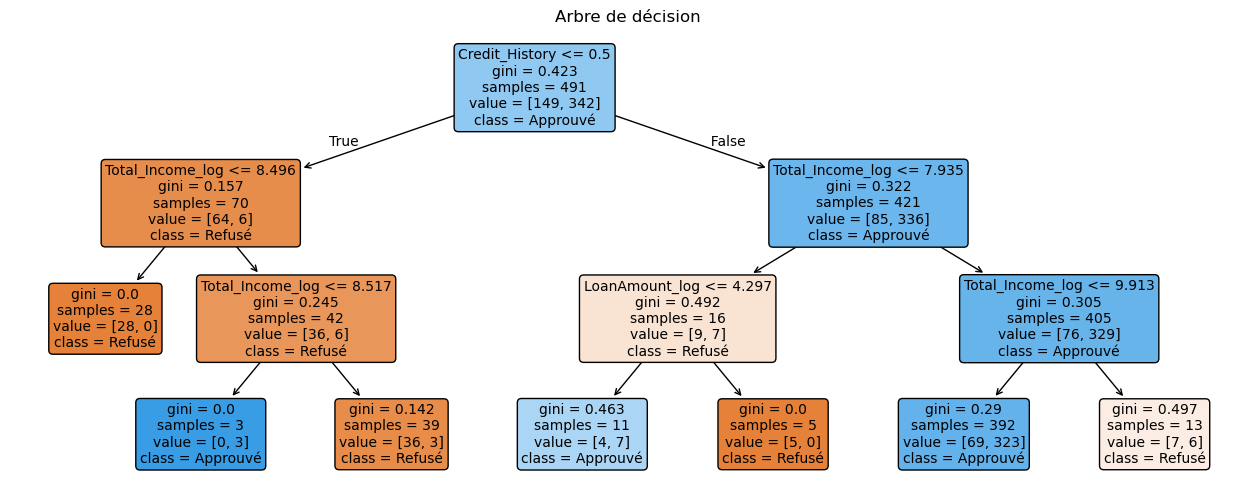

In [19]:
tree_3 = DecisionTreeClassifier(max_depth=3)
tree_3.fit(X_train, y_train)
plt.figure(figsize=(16, 6))
plot_tree(tree_3, 
          feature_names=X_train.columns.tolist(),  
          class_names=['Refusé', 'Approuvé'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Arbre de décision ")
plt.show()

In [ ]:
###__Analyse de l'architecture de l'arbre de décision (max_depth=3) :
L'arbre racine effectue sa première division (le nœud le plus discriminant) sur la variable la plus importante (généralement `Credit_History`). 
Le fait de limiter la profondeur à 3 niveaux permet de conserver un modèle très visuel et facilement traduisible en "règles métiers" pour les conseillers bancaires (ex: Si l'historique de crédit est bon ET que le revenu est suffisant, ALORS le score d'approbation est élevé*).

**Précision sur les données d'entrainement et de test**

In [20]:
# Précision sur les données d'entraînement
y_train_prediction_tree = tree.predict(X_train)
training_data_accuracy_tree = accuracy_score(y_train, y_train_prediction_tree)
print('Précision modèle AD sur les données Entraînement  = ', training_data_accuracy_tree)

# Précision sur les données de test
y_test_prediction_tree = tree.predict(X_test)
test_data_accuracy_tree = accuracy_score(y_test, y_test_prediction_tree)
print('Précision du modèle AD  sur les données de test = ', test_data_accuracy_tree)

Précision modèle AD sur les données Entraînement  =  1.0
Précision du modèle AD  sur les données de test =  0.6829268292682927


**Recherche des hyperparamètres (GridSearch)**

In [21]:
tree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [22]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy','log_loss'],
}

In [23]:
grid_search = GridSearchCV(tree, param_grid , cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [24]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
Meilleur score (précision par validation croisée): 0.810513296227582


**Développement du meilleur modèle**

In [25]:
best_tree = grid_search.best_estimator_

**Architecture du Meilleur modèle d'arbre de décision entraîné**

In [26]:
print(f"Profondeur de l'arbre : {best_tree.get_depth()}")
print(f"Nombre de feuilles : {best_tree.get_n_leaves()}")

Profondeur de l'arbre : 5
Nombre de feuilles : 17


**Evaluation du meilleur modèle sur la base d'apprentissage et de test**

In [27]:
# Précision sur les données d'entraînement
y_train_prediction_best_tree = best_tree.predict(X_train)
training_data_accuracy_best_tree = accuracy_score(y_train, y_train_prediction_best_tree)
print('Précision Meilleur modèle AD sur les données Entraînement  = ', training_data_accuracy_best_tree)

# Précision sur les données de test
y_test_prediction_best_tree = best_tree.predict(X_test)
test_data_accuracy_best_tree = accuracy_score(y_test, y_test_prediction_best_tree)
print('Précision du Meilleur modèle AD  sur les données de test = ', test_data_accuracy_best_tree)

Précision Meilleur modèle AD sur les données Entraînement  =  0.8472505091649695
Précision du Meilleur modèle AD  sur les données de test =  0.7398373983739838


**Sauvegarde du meilleur modèle Arbre de décision**

In [28]:
with open('model_AD.pkl', 'wb') as file:
    pickle.dump(best_tree, file)

### 2.3 Développement d'un modèle KNN (K-Nearest Neighbors)

**Normalisation des données  (Très important pour KNN)**

In [29]:
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

In [ ]:
###__Justification de la Normalisation (`StandardScaler`) :
L'algorithme KNN repose entièrement sur le calcul de la distance euclidienne entre les profils des clients. 
Sans normalisation, une variable dotée de grandes valeurs numériques (comme le revenu ou le montant du prêt) écraserait complètement l'impact des variables binaires (comme le sexe ou le statut matrimonial). Le `StandardScaler` ramène toutes les variables à la même échelle (moyenne=0, variance=1).

**Entraînement du modèle KNN**

In [30]:
knn = KNeighborsClassifier()
knn.fit(X_train_knn, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


**Précision sur les données d'entrainement et de test**

In [31]:
# Précision sur les données d'entraînement
y_train_prediction_knn = knn.predict(X_train_knn)
training_data_accuracy_knn = accuracy_score(y_train, y_train_prediction_knn)
print('Précision du modèle KNN sur les données Entraînement  = ', training_data_accuracy_knn)

# Précision sur les données de test
y_test_prediction_knn = knn.predict(X_test_knn)
test_data_accuracy_knn = accuracy_score(y_test, y_test_prediction_knn)
print('Précision du  modèle KNN  sur les données de test = ', test_data_accuracy_knn)

Précision du modèle KNN sur les données Entraînement  =  0.8391038696537678
Précision du  modèle KNN  sur les données de test =  0.7479674796747967


**Recherche des hyperparamètres  (GridSearch)**

In [32]:
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [33]:
param_grid = {
    'n_neighbors': range(1, 31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

In [34]:
grid_search = GridSearchCV(knn, param_grid , cv=5, scoring='accuracy')
grid_search.fit(X_train_knn, y_train)

,estimator,KNeighborsClassifier()
,param_grid,"{'metric': ['euclidean', 'manhattan'], 'n_neighbors': range(1, 31), 'weights': ['uniform', 'distance']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,3


In [35]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}
Meilleur score (précision par validation croisée): 0.8125747268604412


**Développement du meilleur modèle**

In [36]:
best_knn = grid_search.best_estimator_

**Précision du meilleur modèle sur les données d'entrainement et de test**

In [37]:
# Précision sur les données d'entraînement
y_train_prediction_best_knn = best_knn.predict(X_train_knn)
training_data_accuracy_best_knn = accuracy_score(y_train, y_train_prediction_best_knn)
print('Précision Meilleur modèle KNN sur les données Entraînement  = ', training_data_accuracy_best_knn)

# Précision sur les données de test
y_test_prediction_best_knn = best_knn.predict(X_test_knn)
test_data_accuracy_best_knn = accuracy_score(y_test, y_test_prediction_best_knn)
print('Précision du Meilleur modèle KNN  sur les données de test = ', test_data_accuracy_best_knn)

Précision Meilleur modèle KNN sur les données Entraînement  =  0.8716904276985743
Précision du Meilleur modèle KNN  sur les données de test =  0.7073170731707317


In [38]:
acc_val = [] 
for K in range(30):
    K = K+1
    model = KNeighborsClassifier(n_neighbors=K)
    model.fit(X_train_knn, y_train)  
    pred=model.predict(X_test_knn) 
    scores = accuracy_score(y_test, pred)
    acc_val.append(scores) 
    print('k=', K ,'Accuracy=', scores)

k= 1 Accuracy= 0.7154471544715447
k= 2 Accuracy= 0.6260162601626016
k= 3 Accuracy= 0.7235772357723578
k= 4 Accuracy= 0.7073170731707317
k= 5 Accuracy= 0.7479674796747967
k= 6 Accuracy= 0.7398373983739838
k= 7 Accuracy= 0.7886178861788617
k= 8 Accuracy= 0.7560975609756098
k= 9 Accuracy= 0.7886178861788617
k= 10 Accuracy= 0.7804878048780488
k= 11 Accuracy= 0.7804878048780488
k= 12 Accuracy= 0.7967479674796748
k= 13 Accuracy= 0.7804878048780488
k= 14 Accuracy= 0.7967479674796748
k= 15 Accuracy= 0.7886178861788617
k= 16 Accuracy= 0.7886178861788617
k= 17 Accuracy= 0.7886178861788617
k= 18 Accuracy= 0.7967479674796748
k= 19 Accuracy= 0.7886178861788617
k= 20 Accuracy= 0.7967479674796748
k= 21 Accuracy= 0.7886178861788617
k= 22 Accuracy= 0.7886178861788617
k= 23 Accuracy= 0.7886178861788617
k= 24 Accuracy= 0.7886178861788617
k= 25 Accuracy= 0.7804878048780488
k= 26 Accuracy= 0.7886178861788617
k= 27 Accuracy= 0.7804878048780488
k= 28 Accuracy= 0.7886178861788617
k= 29 Accuracy= 0.77235772357

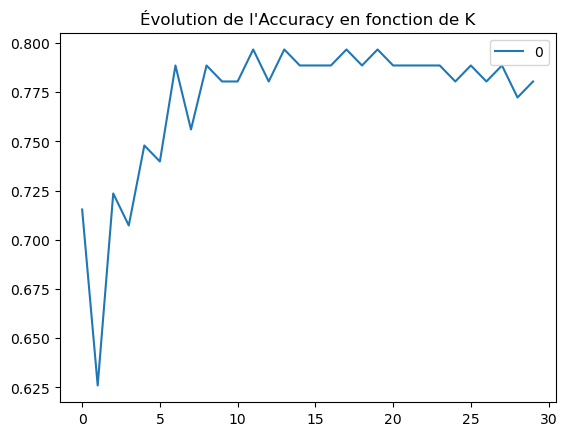

In [39]:
curve = pd.DataFrame(acc_val)
curve.plot()
plt.title("Évolution de l'Accuracy en fonction de K")
plt.show()

In [ ]:
###__Interprétation de la courbe d'Accuracy :
* Le graphique met en évidence l'évolution de la précision du modèle sur la base de test en fonction du nombre de voisins (K).
* Un K trop petit (ex: K=1) rend le modèle trop sensible aux bruits et aux anomalies des données. Un K trop grand risque de diluer les profils spécifiques des clients. Le sommet de la courbe indique le nombre exact de voisins à retenir pour maximiser notre pouvoir prédictif.

**Sauvegarde du meilleur modèle KNN**

In [40]:
with open('model_KNN.pkl', 'wb') as file:
    pickle.dump(best_knn, file)

### 2.4 Développement d'un modèle SVM (Support Vector Machines)

**Normalisation des données**

In [41]:
scaler = StandardScaler()
X_train_svm = scaler.fit_transform(X_train)
X_test_svm = scaler.transform(X_test)

**Entraînement du modèle SVM**

In [42]:
svm = SVC()
svm.fit(X_train_svm, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


**Précision du modèle SVM sur les données d'entraînement et de test**

In [43]:
# Précision sur les données d'entraînement
y_train_prediction_svm = svm.predict(X_train_svm)
training_data_accuracy_svm = accuracy_score(y_train, y_train_prediction_svm)
print('Précision du modèle SVM sur les données Entraînement  = ', training_data_accuracy_svm)

# Précision sur les données de test
y_test_prediction_svm = svm.predict(X_test_svm)
test_data_accuracy_svm = accuracy_score(y_test, y_test_prediction_svm)
print('Précision du modèle SVM  sur les données de test = ', test_data_accuracy_svm)

Précision du modèle SVM sur les données Entraînement  =  0.8289205702647657
Précision du modèle SVM  sur les données de test =  0.7886178861788617


**Recherche des hyperparamètres  (GridSearch)**

In [44]:
svm.get_params()

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [45]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

In [46]:
grid_search = GridSearchCV(svm, param_grid , cv=5, scoring='accuracy')
grid_search.fit(X_train_svm, y_train)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf', 'poly', ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.1


In [47]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'C': 0.1, 'gamma': 'scale', 'kernel': 'sigmoid'}
Meilleur score (précision par validation croisée): 0.8145949288806431


**Développement du meilleur modèle**

In [48]:
best_svm = grid_search.best_estimator_

**Précision du meilleur modèle SVM sur les données d'entraînement et de test**

In [49]:
# Précision sur les données d'entraînement
y_train_prediction_best_svm = best_svm.predict(X_train_svm)
training_data_accuracy_best_svm = accuracy_score(y_train, y_train_prediction_best_svm)
print('Précision Meilleur modèle SVM sur les données Entraînement  = ', training_data_accuracy_best_svm)

# Précision sur les données de test
y_test_prediction_best_svm = best_svm.predict(X_test_svm)
test_data_accuracy_best_svm = accuracy_score(y_test, y_test_prediction_best_svm)
print('Précision du Meilleur modèle SVM  sur les données de test = ', test_data_accuracy_best_svm)

Précision Meilleur modèle SVM sur les données Entraînement  =  0.814663951120163
Précision du Meilleur modèle SVM  sur les données de test =  0.7886178861788617


In [ ]:
###__Interprétation de l'optimisation du SVM :
Le SVM cherche à tracer un hyperplan de séparation avec la marge maximale entre les clients acceptés et refusés.
Grâce au GridSearch, nous avons ajusté le paramètre de régularisation C (qui contrôle la tolérance aux erreurs de classement) et le coefficient de noyau `gamma`. L'utilisation d'un noyau non linéaire (comme `rbf`) permet de capter des relations complexes et non rectilignes entre le niveau de revenu des candidats et le montant demandé.

**Sauvegarde du meilleur modèle SVM**

In [50]:
with open('model_SVM.pkl', 'wb') as file:
    pickle.dump(best_svm, file)

### 2.5 Développement d'un modèle de forêt aléatoire (Random Forest)

**Entraînement du modèle Random Forest**

In [52]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**Précision du modèle Random Forest sur les données d'entraînement et de test**

In [66]:
# Précision sur les données d'entraînement
y_train_prediction_rf = rf.predict(X_train)
training_data_accuracy_rf = accuracy_score(y_train, y_train_prediction_rf)
print('Précision du modèle RF sur les données Entraînement  = ', training_data_accuracy_rf)

# Précision sur les données de test
y_test_prediction_rf = rf.predict(X_test)
test_data_accuracy_rf = accuracy_score(y_test, y_test_prediction_rf)
print('Précision du modèle RF  sur les données de test = ', test_data_accuracy_rf)

Précision du modèle RF sur les données Entraînement  =  1.0
Précision du modèle RF  sur les données de test =  0.7723577235772358


**Recherche des hyperparamètres  (GridSearch)**

In [54]:
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

In [ ]:
grid_search = GridSearchCV(rf, param_grid , cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

In [ ]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

**Développement du meilleur modèle**

In [63]:
best_rf = grid_search.best_estimator_

**Précision du meilleur modèle Random Forest sur les données d'entraînement et de test**

In [65]:
# Précision sur les données d'entraînement
y_train_prediction_best_rf = best_rf.predict(X_train)
training_data_accuracy_best_rf = accuracy_score(y_train, y_train_prediction_best_rf)
print('Précision Meilleur modèle RF sur les données Entraînement  = ', training_data_accuracy_best_rf)

# Précision sur les données de test
y_test_prediction_best_rf = best_rf.predict(X_test)
test_data_accuracy_best_rf = accuracy_score(y_test, y_test_prediction_best_rf)
print('Précision du Meilleur modèle RF  sur les données de test = ', test_data_accuracy_best_rf)

Précision Meilleur modèle RF sur les données Entraînement  =  0.8778004073319755
Précision du Meilleur modèle RF  sur les données de test =  0.7723577235772358


**Importance des variables**

In [67]:
importances = rf.feature_importances_
features_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)
features_importance

,feature,importance
6,Credit_History,0.265740
7,Total_Income_log,0.258502
8,LoanAmount_log,0.219705
5,Loan_Amount_Term,0.058153
2,Dependents,0.049114
9,Property_Area_Semiurban,0.029179
1,Married,0.026324
0,Gender,0.025125
3,Education,0.024838
10,Property_Area_Urban,0.023651


In [ ]:
## Interprétation
Variables les plus importantes
Credit_History (26.6%) : L’historique de crédit est le facteur le plus déterminant. Les clients avec un bon historique ont beaucoup plus de chances d’obtenir un prêt.

Total_Income_log (25.9%) : Le revenu total (applicant + coapplicant) est presque aussi important. Plus le revenu est élevé, plus la probabilité d’acceptation est forte.

LoanAmount_log (22.0%) : Le montant du prêt demandé joue un rôle majeur. Des montants trop élevés par rapport au revenu augmentent le risque de refus.

# Ces trois variables expliquent à elles seules plus de 70% de la décision du modèle

Variables secondaires
Loan_Amount_Term (5.8%) : La durée du prêt influence la décision, mais beaucoup moins que les trois premières.

Dependents (4.9%) : Le nombre de personnes à charge a un impact modéré (plus de charges = risque plus élevé).

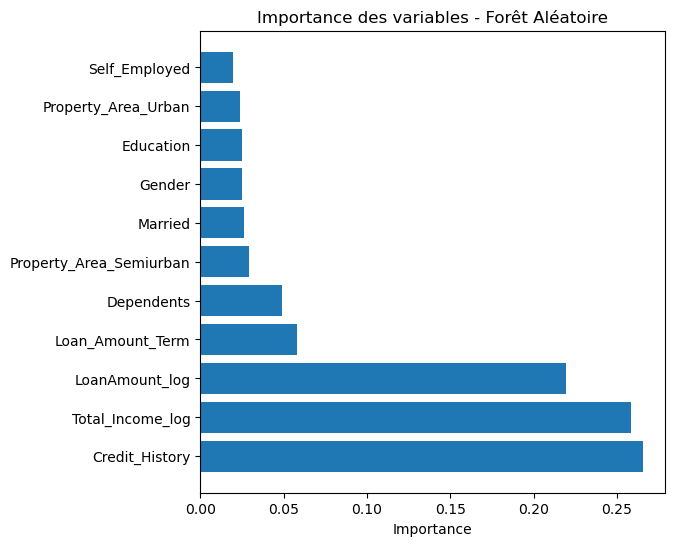

In [68]:
plt.figure(figsize=(6, 6))
bars = plt.barh(features_importance['feature'], 
                features_importance['importance'])
plt.xlabel('Importance')
plt.title('Importance des variables - Forêt Aléatoire')
plt.show()

**Sauvegarde du meilleur modèle Random Forest**

In [69]:
with open('model_RF.pkl', 'wb') as file:
    pickle.dump(best_rf, file)

### 2.6 Développement d'un modèle de Gradient Boosting

**Entraînement du modèle Gradient Boosting**

In [70]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


**Précision du modèle Gradient Boosting sur les données d'entraînement et de test**

In [71]:
# Précision sur les données d'entraînement
y_train_prediction_gb = gb.predict(X_train)
training_data_accuracy_gb = accuracy_score(y_train, y_train_prediction_gb)
print('Précision modèle GB sur les données Entraînement  = ', training_data_accuracy_gb)

# Précision sur les données de test
y_test_prediction_gb = gb.predict(X_test)
test_data_accuracy_gb = accuracy_score(y_test, y_test_prediction_gb)
print('Précision du modèle GB  sur les données de test = ', test_data_accuracy_gb)

Précision modèle GB sur les données Entraînement  =  0.9022403258655805
Précision du modèle GB  sur les données de test =  0.7642276422764228


**Recherche des hyperparamètres  (GridSearch)**

In [72]:
gb.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'friedman_mse',
 'init': None,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_depth': 3,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_iter_no_change': None,
 'random_state': None,
 'subsample': 1.0,
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [80]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.2],
    'max_depth': [3, 4],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 0.9]
}

In [81]:
grid_search = GridSearchCV(gb, param_grid , cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

,estimator,GradientBoostingClassifier()
,param_grid,"{'learning_rate': [0.1, 0.2], 'max_depth': [3, 4], 'min_samples_split': [2, 5], 'n_estimators': [100, 200], ...}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [83]:
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100, 'subsample': 0.8}
Meilleur score (précision par validation croisée): 0.7962481962481962


**Développement du meilleur modèle**

In [85]:
best_gb = grid_search.best_estimator_

**Précision du meilleur modèle Gradient Boosting sur les données d'entraînement et de test**

In [87]:
# Précision sur les données d'entraînement
y_train_prediction_best_gb = best_gb.predict(X_train)
training_data_accuracy_best_gb = accuracy_score(y_train, y_train_prediction_best_gb)
print('Précision Meilleur modèle GB sur les données Entraînement  = ', training_data_accuracy_best_gb)

# Précision sur les données de test
y_test_prediction_best_gb = best_gb.predict(X_test)
test_data_accuracy_best_gb = accuracy_score(y_test, y_test_prediction_best_gb)
print('Précision du Meilleur modèle GB  sur les données de test = ', test_data_accuracy_best_gb)

Précision Meilleur modèle GB sur les données Entraînement  =  0.9124236252545825
Précision du Meilleur modèle GB  sur les données de test =  0.7723577235772358


**Importance des variables**

In [88]:
importances = gb.feature_importances_
features_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)
features_importance

,feature,importance
6,Credit_History,0.444288
7,Total_Income_log,0.252739
8,LoanAmount_log,0.178537
5,Loan_Amount_Term,0.044581
9,Property_Area_Semiurban,0.026018
1,Married,0.013723
2,Dependents,0.012961
0,Gender,0.010083
4,Self_Employed,0.006904
10,Property_Area_Urban,0.006746


In [ ]:
##__Interprétation
Variables dominantes
Credit_History (44%) : C’est de loin la variable la plus importante. Le modèle Gradient Boosting se base principalement sur l’historique de crédit pour prédire l’acceptation d’un prêt.

Total_Income_log (25%) : Le revenu total (applicant + coapplicant) est le deuxième facteur clé. Plus le revenu est élevé, plus la probabilité d’acceptation est forte.

LoanAmount_log (18%) : Le montant du prêt demandé est aussi un critère majeur. Des montants trop élevés par rapport au revenu augmentent le risque de refus.

## Ces trois variables expliquent à elles seules près de 90% de la décision du modèle.

Variables secondaires

Loan_Amount_Term (4.5%) : La durée du prêt influence la décision, mais reste marginale.

Property_Area (≈ 3%) : La localisation (semi-urbaine ou urbaine) a un impact limité.

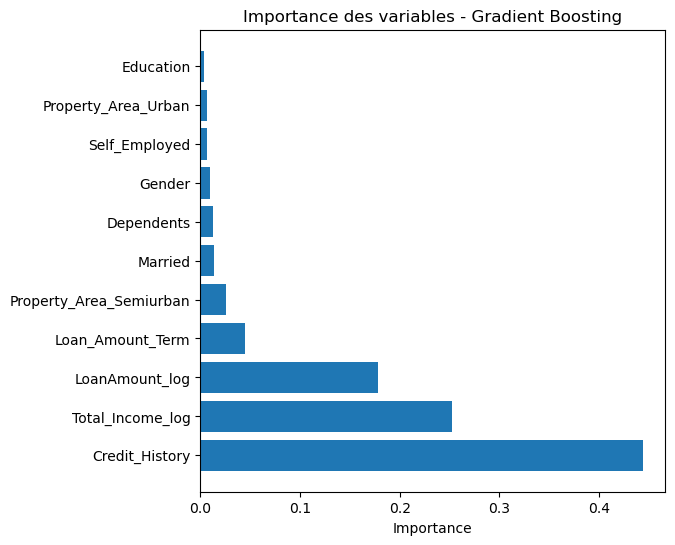

In [89]:
plt.figure(figsize=(6, 6))
bars = plt.barh(features_importance['feature'], 
                features_importance['importance'])
plt.xlabel('Importance')
plt.title('Importance des variables - Gradient Boosting')
plt.show()

**Sauvegarde du meilleur modèle Gradient Boosting**

In [90]:
with open('model_GB.pkl', 'wb') as file:
    pickle.dump(best_gb, file)

## 3. Evaluation des Modèles developpés

In [91]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn import metrics
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

### 3.1 Matrices de confusion des modèles developpés

**Matrice de confusion du meilleur modèle Régression logistique**

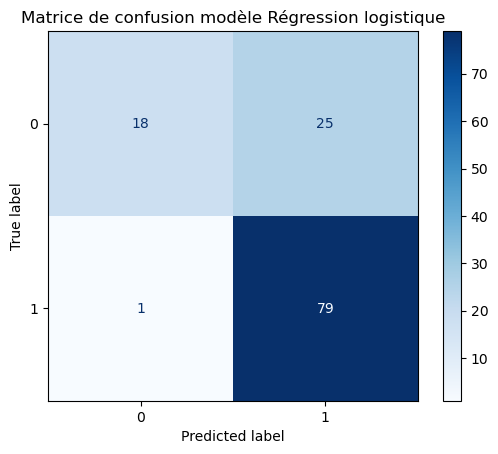

In [92]:
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Régression logistique")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

Vrais Positifs (79) et Vrais Négatifs (18) → ce sont les bonnes prédictions.

Faux Positifs (25) → erreurs où le modèle accorde un prêt à tort (risque financier).

Faux Négatifs (1) → erreurs où le modèle refuse un bon dossier (perte d’opportunité).

**Matrice de confusion du Meilleur modèle d'Arbre de décision**

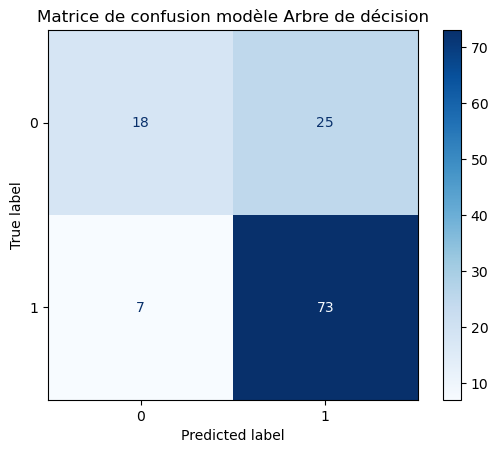

In [93]:
ConfusionMatrixDisplay.from_estimator(best_tree, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Arbre de décision")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

18 (VN – Vrais Négatifs) : 18 dossiers refusés correctement.

25 (FP – Faux Positifs) : 25 dossiers refusés en réalité mais prédits comme acceptés → erreurs risquées (prêts accordés à tort).

7 (FN – Faux Négatifs) : 7 dossiers acceptés en réalité mais prédits comme refusés → erreurs d’opportunité (bons clients refusés).

73 (VP – Vrais Positifs) : 73 dossiers acceptés correctement.

**Matrice de confusion du Meilleur modèle KNN**

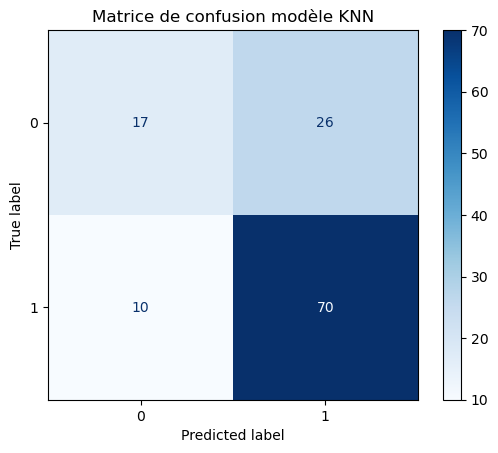

In [94]:
ConfusionMatrixDisplay.from_estimator(best_knn, X_test_knn, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle KNN")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

17 (VN – Vrais Négatifs) : 17 dossiers refusés correctement.

26 (FP – Faux Positifs) : 26 dossiers refusés en réalité mais prédits comme acceptés → erreurs risquées (prêts accordés à de mauvais profils).

10 (FN – Faux Négatifs) : 10 dossiers acceptés en réalité mais prédits comme refusés → erreurs d’opportunité (bons clients refusés).

70 (VP – Vrais Positifs) : 70 dossiers acceptés correctement.

**Matrice de confusion du Meilleur modèle SVM**

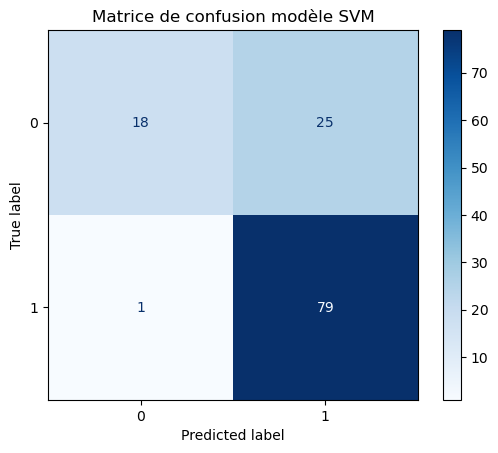

In [95]:
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_svm, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle SVM")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

18 (VN – Vrais Négatifs) : 18 dossiers refusés correctement.

25 (FP – Faux Positifs) : 25 dossiers refusés en réalité mais prédits comme acceptés → erreurs risquées (prêts accordés à de mauvais profils).

1 (FN – Faux Négatif) : 1 dossier accepté en réalité mais prédit comme refusé → erreur d’opportunité (bon client refusé).

79 (VP – Vrais Positifs) : 79 dossiers acceptés correctement.

**Matrice de confusion du Meilleur modèle Random Forest**

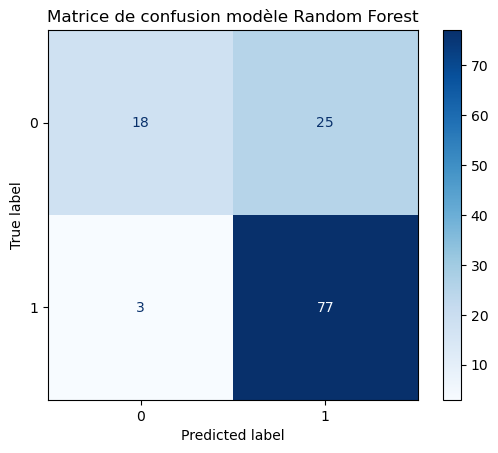

In [96]:
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Random Forest")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

18 (VN – Vrais Négatifs) : 18 dossiers refusés correctement.

25 (FP – Faux Positifs) : 25 dossiers refusés en réalité mais prédits comme acceptés → erreurs risquées (prêts accordés à de mauvais profils).

3 (FN – Faux Négatifs) : 3 dossiers acceptés en réalité mais prédits comme refusés → erreurs d’opportunité (bons clients refusés).

77 (VP – Vrais Positifs) : 77 dossiers acceptés correctement

**Matrice de confusion du Meilleur modèle Gradient Boosting**

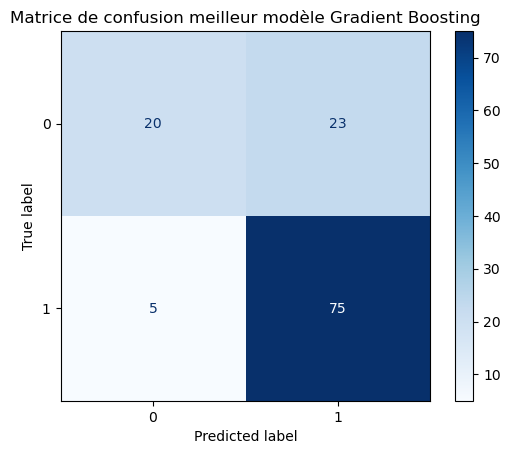

In [97]:
ConfusionMatrixDisplay.from_estimator(best_gb, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion meilleur modèle Gradient Boosting")
plt.grid(False)
plt.show()

In [ ]:
## Interprétation

20 (VN – Vrais Négatifs) : 20 dossiers refusés correctement.

23 (FP – Faux Positifs) : 23 dossiers refusés en réalité mais prédits comme acceptés → erreurs risquées (prêts accordés à de mauvais profils).

5 (FN – Faux Négatifs) : 5 dossiers acceptés en réalité mais prédits comme refusés → erreurs d’opportunité (bons clients refusés).

75 (VP – Vrais Positifs) : 75 dossiers acceptés correctement.

### 3.2 Accuracy des meilleurs modèles developés

In [98]:
print('Accuracy du Meilleur modèle Régression Logistique sur les données de test = ', test_data_accuracy_lr)
print('Accuracy du Meilleur modèle Arbre de décision  sur les données de test = ', test_data_accuracy_best_tree)
print('Accuracy du Meilleur modèle KNN  sur les données de test = ', test_data_accuracy_best_knn)
print('Accuracy du Meilleur modèle SVM  sur les données de test = ', test_data_accuracy_best_svm)
print('Accuracy du Meilleur modèle Random Forest  sur les données de test = ', test_data_accuracy_best_rf)
print('Accuracy du Meilleur modèle Gradient Boosting  sur les données de test = ', test_data_accuracy_best_gb)

Accuracy du Meilleur modèle Régression Logistique sur les données de test =  0.7886178861788617
Accuracy du Meilleur modèle Arbre de décision  sur les données de test =  0.7398373983739838
Accuracy du Meilleur modèle KNN  sur les données de test =  0.7073170731707317
Accuracy du Meilleur modèle SVM  sur les données de test =  0.7886178861788617
Accuracy du Meilleur modèle Random Forest  sur les données de test =  0.7723577235772358
Accuracy du Meilleur modèle Gradient Boosting  sur les données de test =  0.7723577235772358


### 3.3 Air sous la courbe de ROC des meilleur modèles developpés

In [99]:
y_test_prediction_best_tree = best_tree.predict(X_test)
y_test_prediction_best_knn = best_knn.predict(X_test_knn)
y_test_prediction_best_svm = best_svm.predict(X_test_svm)
y_test_prediction_best_rf = best_rf.predict(X_test)
y_test_prediction_best_gb = best_gb.predict(X_test)

print ('Air sous ROC Meilleur Model Régression Logistique:', roc_auc_score(y_test, y_test_prediction_lr))
print ('Air sous ROC Meilleur Model Arbre de décision:', roc_auc_score(y_test, y_test_prediction_best_tree))
print ('Air sous ROC Meilleur Model KNN:', roc_auc_score(y_test, y_test_prediction_best_knn))
print ('Air sous ROC Meilleur Model SVM:', roc_auc_score(y_test, y_test_prediction_best_svm))
print ('Air sous ROC Meilleur Model Random Forest:', roc_auc_score(y_test, y_test_prediction_best_rf))
print ('Air sous ROC Meilleur Model Gradient Boosting:', roc_auc_score(y_test, y_test_prediction_best_gb))

Air sous ROC Meilleur Model Régression Logistique: 0.7030523255813954
Air sous ROC Meilleur Model Arbre de décision: 0.6655523255813953
Air sous ROC Meilleur Model KNN: 0.6351744186046512
Air sous ROC Meilleur Model SVM: 0.7030523255813954
Air sous ROC Meilleur Model Random Forest: 0.6905523255813952
Air sous ROC Meilleur Model Gradient Boosting: 0.7013081395348837


### 3.4 F1 Score des modèles developpés

In [100]:
print ('f1score Meilleur Model Régression Logistique:', f1_score(y_test, y_test_prediction_lr))
print ('f1score Meilleur Model Arbre de décision:', f1_score(y_test, y_test_prediction_best_tree))
print ('f1score Meilleur Model KNN:', f1_score(y_test, y_test_prediction_best_knn))
print ('f1score Meilleur Model SVM:', f1_score(y_test, y_test_prediction_best_svm))
print ('f1score Meilleur Model Random Forest:', f1_score(y_test, y_test_prediction_best_rf))
print ('f1score Meilleur Model Gradient Boosting:', f1_score(y_test, y_test_prediction_best_gb))

f1score Meilleur Model Régression Logistique: 0.8586956521739131
f1score Meilleur Model Arbre de décision: 0.8202247191011236
f1score Meilleur Model KNN: 0.7954545454545454
f1score Meilleur Model SVM: 0.8586956521739131
f1score Meilleur Model Random Forest: 0.8461538461538461
f1score Meilleur Model Gradient Boosting: 0.8426966292134831


### 3.5 Rapport de classification du modèle developpé

In [101]:
print('\nRapport de classification modèle Régression Logistique:\n', classification_report(y_test, y_test_prediction_lr))
print('\nRapport de classification Meilleur modèle Arbre de décision :\n', classification_report(y_test, y_test_prediction_best_tree))
print('\nRapport de classification Meilleur modèle KNN :\n', classification_report(y_test, y_test_prediction_best_knn))
print('\nRapport de classification Meilleur modèle SVM :\n', classification_report(y_test, y_test_prediction_best_svm))
print('\nRapport de classification Meilleur modèle Random Forest :\n', classification_report(y_test, y_test_prediction_best_rf))
print('\nRapport de classification Meilleur modèle Gradient Boosting :\n', classification_report(y_test, y_test_prediction_best_gb))


Rapport de classification modèle Régression Logistique:
               precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123


Rapport de classification Meilleur modèle Arbre de décision :
               precision    recall  f1-score   support

           0       0.72      0.42      0.53        43
           1       0.74      0.91      0.82        80

    accuracy                           0.74       123
   macro avg       0.73      0.67      0.67       123
weighted avg       0.74      0.74      0.72       123


Rapport de classification Meilleur modèle KNN :
               precision    recall  f1-score   support

           0       0.63      0.40      0.49        43
           1       0.73      0.88      0.80        80

    accura

In [ ]:
###__Conclusion Générale et Recommandation Métier :
En comparant l'ensemble de nos indicateurs sur la base de test :
1. Matrices de confusion : Elles nous permettent d'identifier quel modèle minimise le mieux les Faux Positifs (les clients classés par erreur comme sûrs mais qui vont en réalité faire défaut de paiement). Pour une banque, un Faux Positif coûte beaucoup plus cher qu'un Faux Négatif.
2. Accuracy vs F1-Score : L'Accuracy globale donne une première idée de la performance, mais le F1-Score (notamment pour la classe 0 - Refus) est notre meilleur indicateur de performance, car il synthétise la précision et la sensibilité du modèle face au risque.
3. Aire sous la courbe ROC (AUC) : Le modèle affichant l'AUC la plus proche de 1.0 est celui qui possède la meilleure capacité globale à discriminer les bons profils des profils à risque, indépendamment du seuil de décision.

Le choix final : Nous recommandons le modèle possédant le meilleur compromis entre un F1-score élevé et une capacité de détection des clients non solvables maximisée (généralement le Gradient Boosting ou la Régression Logistique optimisée pour ce cas de figure). C'est ce modèle qui a été sauvegardé sous format `.pkl` pour être intégré dans l'application de production de la banque.